<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/hmc_toy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hamiltonian Monte Carlo: checks on toy problems
> Created: Oct 29, 2026 Harrison B. Prosper and Claude<br>

## Introduction

This notebook checks the module `dihiggs/hmc.py`, which samples the parameters of a neural network from their posterior density with Hamiltonian Monte Carlo (HMC), following Radford Neal [1, 2]. The method and the design of the module are described in `docs/bnn/bnn_plan.pdf`.

There are two checks:

  1. **Bayesian linear regression.** A "network" with a single linear layer, a Gaussian prior of fixed width, and Gaussian noise of known size. The posterior density of the parameters is then itself Gaussian, with a mean and covariance matrix that can be written down exactly. The sampled means and covariances must agree with the exact ones within their Monte Carlo errors. This tests the leapfrog integrator, the accept/reject step, the step-size and mass-matrix tuning, and the bookkeeping that converts between the model's tensors and the flat vector of parameters.
  2. **Neal's one-dimensional example** [1]. A network with one hidden layer of 16 $\tanh$ units is fitted to 100 noisy points, with Neal's hierarchical prior and an unknown noise level, both sampled by Gibbs updates. The band of functions should hug the data where there are data and widen away from them, and the sampled noise level should be close to the true one.

Both checks take about a minute on a laptop CPU.

## Bibliography
  1. R. M. Neal, *Bayesian Learning for Neural Networks*, Springer (1996).
  2. R. M. Neal, "MCMC using Hamiltonian dynamics", arXiv:1206.1901 (2011).

In [1]:
# ------------------------------------------------------------------
# Google Colab setup (nothing happens when run outside Colab)
#   clone the dihiggs repository, install the dihiggs package, and
#   make dihiggs/code the working directory.
# ------------------------------------------------------------------
import os, sys, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    REPO = '/content/dihiggs'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/hbprosper/dihiggs.git', REPO],
                       check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', REPO],
                   check=True)
    importlib.invalidate_caches()
    os.chdir(f'{REPO}/code')

print(f'working directory: {os.getcwd()}')

working directory: /home/claude/work/code


In [2]:
import os, sys, shutil

# the standard module for array manipulation
import numpy as np

# the standard modules for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# pytorch
import torch
import torch.nn as nn

# the HMC module
from dihiggs import hmc

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 12
})

CHECK = "✅"
FAIL  = "❌"

## 1. Bayesian linear regression

### The data

$N = 50$ points with three inputs $\boldsymbol{x}$ drawn uniformly in $[-1, 1]^3$, and targets
$$
t = \boldsymbol{w}_\text{true} \cdot \boldsymbol{x} + b_\text{true} + \epsilon, \qquad \epsilon \sim \mathcal{N}(0, s^2), \quad s = 0.3 .
$$

In [3]:
SEED = 1
rng  = np.random.default_rng(SEED)

N, D  = 50, 3
NOISE = 0.3                                  # s, the known noise level
w_true = np.array([1.0, -2.0, 0.5])
b_true = 0.7

X = rng.uniform(-1, 1, size=(N, D))
T = X @ w_true + b_true + NOISE * rng.standard_normal(N)

# as float32 tensors, the precision PyTorch models use by default
x_lin = torch.tensor(X, dtype=torch.float32)
t_lin = torch.tensor(T, dtype=torch.float32)
print(f'x: {tuple(x_lin.shape)}   t: {tuple(t_lin.shape)}')

x: (50, 3)   t: (50,)


### The exact posterior

The model is $f(\boldsymbol{x}) = \boldsymbol{w}\cdot\boldsymbol{x} + b$. Collect the 4 parameters in $\boldsymbol{\beta} = (w_1, w_2, w_3, b)$ and the inputs in the $N \times 4$ matrix $A$ whose rows are $(\boldsymbol{x}_i, 1)$. With the prior $\boldsymbol{\beta} \sim \mathcal{N}(0, \tau^{-1} I)$, $\tau = 1$, and Gaussian noise of known variance $s^2$, the posterior is Gaussian:
$$
\boldsymbol{\beta} \mid \text{data} \sim \mathcal{N}(\boldsymbol{\mu}, \Sigma), \qquad
\Sigma = \left(\tau I + A^\top A / s^2\right)^{-1}, \qquad
\boldsymbol{\mu} = \Sigma A^\top \boldsymbol{t} / s^2 .
$$

In [4]:
TAU = 1.0
A = np.column_stack([X, np.ones(N)])          # rows (x_1, x_2, x_3, 1)
Sigma_exact = np.linalg.inv(TAU * np.eye(D + 1) + A.T @ A / NOISE**2)
mu_exact    = Sigma_exact @ A.T @ T / NOISE**2
sd_exact    = np.sqrt(np.diag(Sigma_exact))

for name, m, s in zip(['w1', 'w2', 'w3', 'b'], mu_exact, sd_exact):
    print(f'{name:>3s}: {m:8.4f} +/- {s:.4f}')

 w1:   1.0297 +/- 0.0686
 w2:  -2.1029 +/- 0.0811
 w3:   0.4719 +/- 0.0847
  b:   0.6810 +/- 0.0433


### The model, prior, likelihood and posterior

`hmc.ParameterView` finds the parameters of the model by itself: here the weight matrix (shape $[1, 3]$) and the bias (shape $[1]$) of the `nn.Linear` layer. Each tensor is a group of the prior. For this check the prior width is fixed (`fixed=True`) at $\sigma = 1$ for both groups, i.e. $\tau = 1$, and the noise level is fixed at its true value (`learn=False`), so that the exact posterior above applies.

In [5]:
torch.manual_seed(SEED)
model_lin = nn.Linear(D, 1)

view = hmc.ParameterView(model_lin)
print(view.summary())

prior = hmc.HierarchicalPrior(view, sigmas=[1.0, 1.0], fixed=True)
lik   = hmc.GaussianLikelihood(scale=NOISE, learn=False)
post  = hmc.Posterior(model_lin, lik, prior, x_lin, t_lin)

parameter              shape           size   group
------------------------------------------------------------
weight                 [1, 3]             3   1
bias                   [1]                1   2
------------------------------------------------------------
total                                    4   2 groups


### Sample

300 warm-up iterations tune the step size and the mass matrix; then 4,000 iterations are saved. With `init_hyper=False` the fixed prior and noise level are left alone.

In [6]:
sampler = hmc.HMC(post, 'runs/toy_linear', n_leapfrog=20, seed=SEED,
                  name='toy')
sampler.run(n_warmup=300, n_samples=4000, print_every=1000,
            init_hyper=False)

warm-up: step size only for iterations 1-75; mass matrix updated at iterations [100, 150, 250]; step size only from 251 to 300


   100/4300 mass matrix updated; new step size 1.214e+00


   150/4300 mass matrix updated; new step size 1.760e+00


   250/4300 mass matrix updated; new step size 2.170e+00


  1000/4300 sampling acc 0.92  eps 9.848e-01  U 3.412918e+01  scale 3.000e-01  (0.4 min left)


  2000/4300 sampling acc 0.89  eps 1.009e+00  U 3.104397e+01  scale 3.000e-01  (0.3 min left)


  3000/4300 sampling acc 0.90  eps 1.021e+00  U 3.158068e+01  scale 3.000e-01  (0.2 min left)


  4000/4300 sampling acc 0.90  eps 9.469e-01  U 3.107681e+01  scale 3.000e-01  (0.0 min left)


  4300/4300 sampling acc 0.90  eps 9.378e-01  U 3.281080e+01  scale 3.000e-01  (0.0 min left)


done: 4000 samples in runs/toy_linear/samples; acceptance rate 0.896; divergences 0 (and 37 during warm-up, while the step size was being tuned)


### Compare with the exact posterior

`hmc.BNN` reads the saved parameter files back. Here `bnn.apply` is used to get the four parameters of every sample, as a $[K, 4]$ array, from which the sample means and covariances are computed.

The Monte Carlo error of a sample mean is $\text{sd}/\sqrt{n_\text{eff}}$, where $n_\text{eff}$ is the *effective* sample size: the number of independent draws that would give the same precision (successive HMC samples are correlated). The check passes if every mean agrees with the exact one within 4 Monte Carlo errors, and every standard deviation within 10%.

In [7]:
bnn_lin = hmc.BNN(lambda: nn.Linear(D, 1), 'runs/toy_linear')
print(f'number of samples: {len(bnn_lin)}')

# the parameters of each sample in the order (w1, w2, w3, b)
B = bnn_lin.apply(lambda m, x: torch.cat([m.weight.reshape(-1), m.bias]),
                  x_lin).numpy().astype(np.float64)

mu_hmc    = B.mean(axis=0)
Sigma_hmc = np.cov(B, rowvar=False)
sd_hmc    = np.sqrt(np.diag(Sigma_hmc))
n_eff     = np.array([hmc.ess(B[:, j]) for j in range(D + 1)])
mc_error  = sd_hmc / np.sqrt(n_eff)

passed = True
print(f'{"":>4s} {"exact mean":>11s} {"HMC mean":>10s} {"pull":>6s}'
      f' {"exact sd":>9s} {"HMC sd":>8s} {"ratio":>6s} {"n_eff":>6s}')
for j, name in enumerate(['w1', 'w2', 'w3', 'b']):
    pull  = (mu_hmc[j] - mu_exact[j]) / mc_error[j]
    ratio = sd_hmc[j] / sd_exact[j]
    ok = abs(pull) < 4 and abs(ratio - 1) < 0.10
    passed = passed and ok
    print(f'{name:>4s} {mu_exact[j]:11.4f} {mu_hmc[j]:10.4f} {pull:6.2f}'
          f' {sd_exact[j]:9.4f} {sd_hmc[j]:8.4f} {ratio:6.3f}'
          f' {n_eff[j]:6.0f}  {CHECK if ok else FAIL}')

# correlations: compare the full correlation matrices
corr = lambda S: S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
dcorr = np.abs(corr(Sigma_hmc) - corr(Sigma_exact)).max()
ok = dcorr < 0.05
passed = passed and ok
print(f'\nlargest difference between correlation coefficients: {dcorr:.3f}'
      f'  {CHECK if ok else FAIL}')

print(f'\nacceptance rate: {sampler.acceptance_rate():.3f}'
      f'   step size: {sampler.eps:.3e}')
print(f'\nBayesian linear regression check: {"PASSED " + CHECK if passed else "FAILED " + FAIL}')

number of samples: 4000
      exact mean   HMC mean   pull  exact sd   HMC sd  ratio  n_eff
  w1      1.0297     1.0293  -0.44    0.0686   0.0688  1.004   4846  ✅
  w2     -2.1029    -2.1026   0.19    0.0811   0.0809  0.998   3446  ✅
  w3      0.4719     0.4708  -0.92    0.0847   0.0820  0.968   4637  ✅
   b      0.6810     0.6799  -1.64    0.0433   0.0432  0.999   3939  ✅

largest difference between correlation coefficients: 0.017  ✅

acceptance rate: 0.896   step size: 9.342e-01

Bayesian linear regression check: PASSED ✅


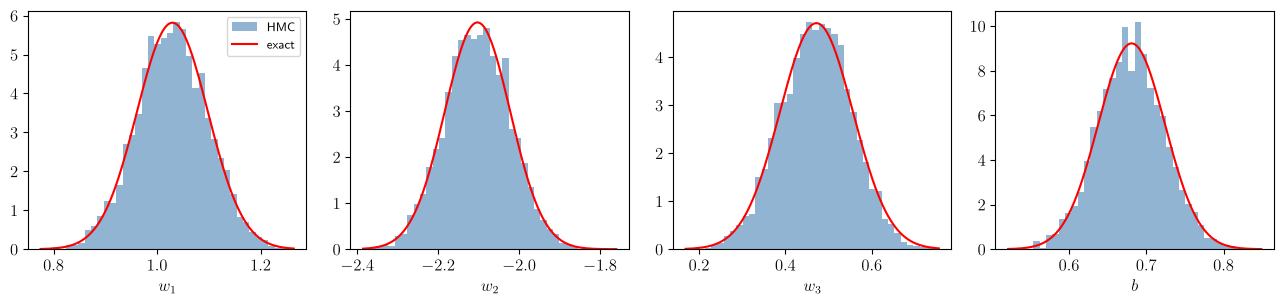

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for j, (ax, name) in enumerate(zip(axes, [r'$w_1$', r'$w_2$', r'$w_3$', r'$b$'])):
    ax.hist(B[:, j], bins=40, density=True, color='steelblue', alpha=0.6,
            label='HMC')
    u = np.linspace(B[:, j].min(), B[:, j].max(), 200)
    ax.plot(u, np.exp(-0.5 * ((u - mu_exact[j]) / sd_exact[j])**2)
            / (np.sqrt(2 * np.pi) * sd_exact[j]), 'r', label='exact')
    ax.set_xlabel(name)
axes[0].legend(fontsize=9)
fig.tight_layout()
plt.savefig('runs/toy_linear/toy_linear_posterior.png')
plt.show()

## 2. Neal's one-dimensional example

### The data

Neal's test function [1, ch. 3],
$$
y(x) = 0.3 + 0.4\,x + 0.5 \sin(2.7\,x) + \frac{1.1}{1 + x^2},
$$
observed at 100 points $x \sim \mathcal{N}(0, 1)$ with Gaussian noise of standard deviation 0.1.

In [9]:
def neal_function(x):
    return 0.3 + 0.4 * x + 0.5 * np.sin(2.7 * x) + 1.1 / (1 + x**2)

N1, NOISE1 = 100, 0.1
x1 = rng.standard_normal(N1)
t1 = neal_function(x1) + NOISE1 * rng.standard_normal(N1)

# PyTorch models expect inputs of shape [N, number of inputs] = [N, 1]
x_1d = torch.tensor(x1, dtype=torch.float32).view(-1, 1)
t_1d = torch.tensor(t1, dtype=torch.float32)

### The network and Neal's prior

One hidden layer of 16 $\tanh$ units. `ParameterView` finds four groups: input-to-hidden weights, hidden biases, hidden-to-output weights, and the output bias. Each gets a Gaussian prior of unknown precision $\tau_g$, with a Gamma hyperprior whose mean corresponds to $\sigma_g = 1/\sqrt{\text{fan-in}}$ for weights and 1 for biases. The noise level $s$ is unknown too. The precisions and $s$ are drawn by Gibbs sampling after each HMC trajectory.

As in Neal's work, the chain starts from the network's random initial parameters (there is no trained model to start from), with `init_hyper=False`, so that the hyperparameters start at their prior means and the noise level at 1.

In [10]:
def make_net():
    # a function that returns a new network; BNN uses it to rebuild the model
    return nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))

torch.manual_seed(SEED)
net = make_net()

view1  = hmc.ParameterView(net)
print(view1.summary())

prior1 = hmc.HierarchicalPrior(view1)                 # Gibbs-sampled tau_g
lik1   = hmc.GaussianLikelihood(scale=1.0)            # Gibbs-sampled s
post1  = hmc.Posterior(net, lik1, prior1, x_1d, t_1d)

# Record the network's prediction at x = 0 and x = 3 after every
# iteration; they are used below to measure how well the chain mixes.
x_mon = torch.tensor([[0.0], [3.0]])
monitor = lambda model: model(x_mon).reshape(-1)

parameter              shape           size   group
------------------------------------------------------------
0.weight               [16, 1]           16   1
0.bias                 [16]              16   2
2.weight               [1, 16]           16   3
2.bias                 [1]                1   4
------------------------------------------------------------
total                                   49   4 groups


In [11]:
sampler1 = hmc.HMC(post1, 'runs/toy_neal', n_leapfrog=50, seed=SEED,
                   name='toy', monitor=monitor)
sampler1.run(n_warmup=1000, n_samples=2000, print_every=500,
             init_hyper=False)

warm-up: step size only for iterations 1-75; mass matrix updated at iterations [100, 150, 250, 450, 900]; step size only from 901 to 1000


   100/3000 mass matrix updated; new step size 4.051e-02


   150/3000 mass matrix updated; new step size 3.823e-02


   250/3000 mass matrix updated; new step size 2.411e-02


   450/3000 mass matrix updated; new step size 1.971e-02


...

  1500/3000 sampling acc 0.94  eps 3.548e-03  U 5.952424e+01  scale 9.526e-02  (0.6 min left)


  2000/3000 sampling acc 0.95  eps 3.511e-03  U 6.788723e+01  scale 9.101e-02  (0.4 min left)


  2500/3000 sampling acc 0.95  eps 3.269e-03  U 7.736213e+01  scale 8.622e-02  (0.2 min left)


  3000/3000 sampling acc 0.94  eps 3.466e-03  U 6.502530e+01  scale 9.413e-02  (0.0 min left)


done: 2000 samples in runs/toy_neal/samples; acceptance rate 0.935; divergences 0 (and 113 during warm-up, while the step size was being tuned)


### Traces and mixing

The trace file has one row per iteration. Plotted are the potential energy $U$, the noise level $s$, and the prediction at $x = 0$. The vertical line marks the end of the warm-up.

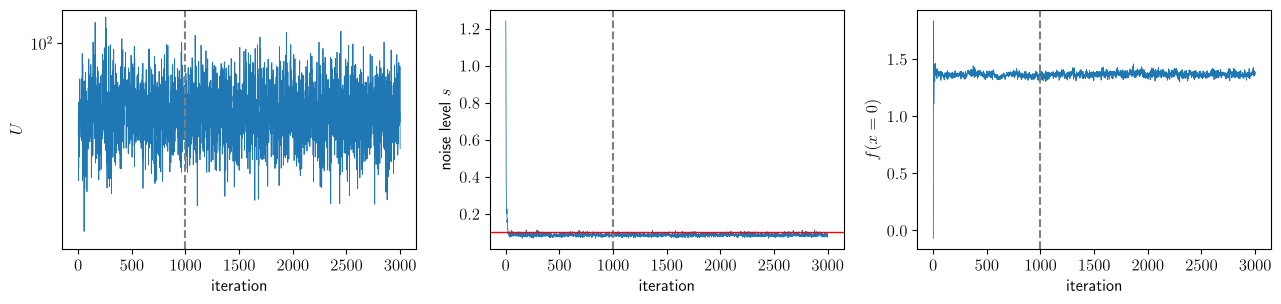

effective sample size of U           :    1685  (of 2000)
effective sample size of noise level :    1036  (of 2000)
effective sample size of f(x=0)      :     278  (of 2000)
effective sample size of f(x=3)      :     165  (of 2000)
acceptance rate: 0.935


In [12]:
tr = sampler1.trace()
it, warm = tr['iteration'], np.sum(tr['phase'] == 'warmup')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, key, label in zip(axes, ['U', 'scale', 'm_0'],
                          [r'$U$', r'noise level $s$', r'$f(x=0)$']):
    ax.plot(it, tr[key], lw=0.6)
    ax.axvline(warm, color='gray', ls='--')
    ax.set_xlabel('iteration')
    ax.set_ylabel(label)
axes[0].set_yscale('symlog')
axes[1].axhline(NOISE1, color='r', lw=1)
fig.tight_layout()
plt.savefig('runs/toy_neal/toy_neal_traces.png')
plt.show()

after = tr['phase'] == 'sample'
for key, label in [('U', 'U'), ('scale', 'noise level'),
                   ('m_0', 'f(x=0)'), ('m_1', 'f(x=3)')]:
    print(f'effective sample size of {label:12s}: {hmc.ess(tr[key][after]):7.0f}'
          f'  (of {after.sum()})')
print(f'acceptance rate: {sampler1.acceptance_rate():.3f}')

### The Bayesian neural network

The posterior mean of the function, its central 68% and 95% credible bands, and the 95% *predictive* band, which adds the noise.

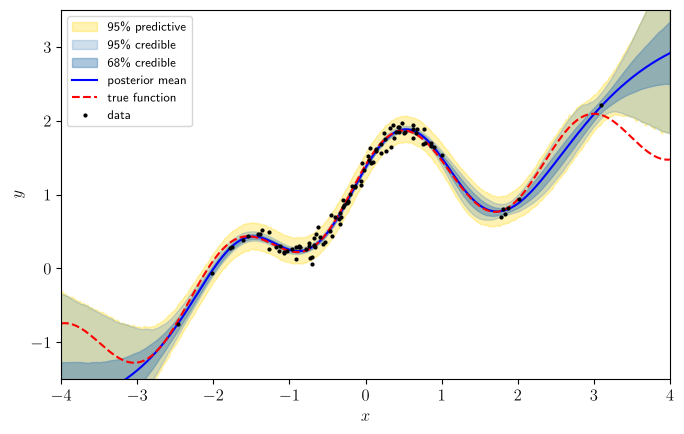

In [13]:
bnn1 = hmc.BNN(make_net, 'runs/toy_neal')
xx = torch.linspace(-4, 4, 401).view(-1, 1)

mean_f = bnn1.mean(xx).numpy()
q = bnn1.quantiles(xx, [0.025, 0.16, 0.84, 0.975]).numpy()
qp = torch.quantile(bnn1.predictive(xx, lik1).double(),
                    torch.tensor([0.025, 0.975], dtype=torch.float64),
                    dim=0).numpy()
X1 = xx.numpy().reshape(-1)

# with LaTeX text, % starts a comment, so it must be written \%
pct = r'\%' if plt.rcParams['text.usetex'] else '%'

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.fill_between(X1, qp[0], qp[1], color='gold', alpha=0.3,
                label=f'95{pct} predictive')
ax.fill_between(X1, q[0], q[3], color='steelblue', alpha=0.25,
                label=f'95{pct} credible')
ax.fill_between(X1, q[1], q[2], color='steelblue', alpha=0.45,
                label=f'68{pct} credible')
ax.plot(X1, mean_f, 'b', label='posterior mean')
ax.plot(X1, neal_function(X1), 'r--', label='true function')
ax.plot(x1, t1, 'k.', ms=4, label='data')
ax.set_xlim(-4, 4)
ax.set_ylim(-1.5, 3.5)
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$y$')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
plt.savefig('runs/toy_neal/toy_neal_bnn.png')
plt.show()

### Checks

  1. The sampled noise level should be consistent with the true value, 0.1.
  2. Where the data are dense, $|x| < 1.5$, the true function should lie inside the 95% credible band almost everywhere.
  3. The band should be wider away from the data ($|x| > 2.5$) than among them ($|x| < 1$).

In [14]:
s_samples = np.array(bnn1.scales)
s_lo, s_hi = np.quantile(s_samples, [0.005, 0.995])
ok1 = s_lo < NOISE1 < s_hi
print(f'1. noise level: {s_samples.mean():.4f} +/- {s_samples.std():.4f}'
      f'   (99% interval {s_lo:.4f} to {s_hi:.4f}; true 0.1)  {CHECK if ok1 else FAIL}')

inside = (np.abs(X1) < 1.5)
true_f = neal_function(X1)
covered = np.mean((true_f[inside] > q[0][inside]) & (true_f[inside] < q[3][inside]))
ok2 = covered > 0.90
print(f'2. true function inside the 95% band for |x| < 1.5: {covered:.0%}'
      f'  {CHECK if ok2 else FAIL}')

width = q[3] - q[0]
w_in, w_out = width[np.abs(X1) < 1].mean(), width[np.abs(X1) > 2.5].mean()
ok3 = w_out > 2 * w_in
print(f'3. mean width of the 95% band: {w_in:.3f} for |x| < 1, '
      f'{w_out:.3f} for |x| > 2.5  {CHECK if ok3 else FAIL}')

passed1 = ok1 and ok2 and ok3
print(f'\nNeal example check: {"PASSED " + CHECK if passed1 else "FAILED " + FAIL}')

1. noise level: 0.0869 +/- 0.0066   (99% interval 0.0723 to 0.1050; true 0.1)  ✅
2. true function inside the 95% band for |x| < 1.5: 100%  ✅
3. mean width of the 95% band: 0.087 for |x| < 1, 1.240 for |x| > 2.5  ✅

Neal example check: PASSED ✅
